In [ ]:
# Importação de Bibliotecas
import numpy as np
import matplotlib.pyplot as plt
import time

In [ ]:
# ----------------------------------------------------------
# Base de Dados: Densidade da Água em Função da Temperatura
# ----------------------------------------------------------
# Fonte: CRC Handbook of Chemistry and Physics, 85ª ed., Seção 6-1.
# Temperatura de 0 °C a 100 °C, com espaçamento uniforme h = 10 °C.
# Densidade em kg/m³ (pressão de 1 atm).

temp = np.array([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)
dens = np.array([999.84, 999.70, 998.20, 995.65, 992.22,
                 988.07, 983.20, 977.76, 971.82, 965.35, 958.37], dtype=float)

print(f"{'Temp (°C)':<12} {'Densidade (kg/m³)'}")
print("-" * 30)
for t, d in zip(temp, dens):
    print(f"{t:<12.0f} {d:.2f}")

Temp (°C)    Densidade (kg/m³)
------------------------------
0            999.84
10           999.70
20           998.20
30           995.65
40           992.22
50           988.07
60           983.20
70           977.76
80           971.82
90           965.35
100          958.37


In [ ]:
# --------------------------------------------
# Pontos de Validação com Referência IAPWS-95
# --------------------------------------------
# Valores de referência extraídos da formulação IAPWS-95 (Wagner & Pruß, 2002),
# considerada o padrão internacional de maior exatidão para propriedades da água.
# Todos os valores são para pressão de 1 atm.
#
# Os pontos foram escolhidos para cobrir:
#   - Interior da tabela (4, 15, 25, 37 °C) — teste de interpolação típica
#   - Ponto de máxima densidade (~3,98 °C) — região de maior não-linearidade
#   - Temperatura corporal (37 °C) — relevância prática
#   - Pontos próximos às bordas (4, 85 °C) — maior risco de oscilação (Runge)

pontos_val = {
     4.0: 999.9720,   # próximo ao máximo de densidade (~3,98 °C)
    15.0: 999.0996,
    25.0: 997.0449,
    37.0: 993.3316,
    55.0: 985.6772,
    85.0: 968.5986,
}

print(f"\n{'Ponto de teste (°C)':<22} {'Referência IAPWS-95 (kg/m³)'}")
print("-" * 48)
for t, r in pontos_val.items():
    print(f"{t:<22.1f} {r:.4f}")


Ponto de teste (°C)    Referência IAPWS-95 (kg/m³)
------------------------------------------------
4.0                    999.9720
15.0                   999.0996
25.0                   997.0449
37.0                   993.3316
55.0                   985.6772
85.0                   968.5986


In [ ]:
# ----------------------------
# Implementações dos Métodos
# ----------------------------

# ── Método 1: Lagrange ────────────────────────────────────────────────────────
def lagrange(x_pts, y_pts, x):

    # Interpolação de Lagrange (forma clássica direta).

    # Cada base polinomial L_i(x) é calculada integralmente a cada chamada,
    # sem nenhuma pré-computação de pesos. Isso a diferencia da forma
    # baricêntrica, que pré-computa w_i = 1 / ∏_{j!=i}(x_i - x_j) e avalia
    # p(x) = [Σ w_i·y_i/(x-x_i)] / [Σ w_i/(x-x_i)], com custo O(n) por
    # avaliação após setup O(n²). Aqui, o custo total é O(n²) por chamada.

    # Complexidade por avaliação: O(n²)
    # - Loop externo: n termos L_i
    # - Loop interno: (n-1) multiplicações e (n-1) divisões por L_i → 2(n-1) ops
    # - Acumulação: 1 multiplicação + 1 adição → 2 ops
    # - Total: n · [2(n-1) + 2] = 2n² operações aritméticas

    n = len(x_pts)
    resultado = 0.0
    for i in range(n):
        L_i = 1.0
        for j in range(n):
            if j != i:
                L_i *= (x - x_pts[j]) / (x_pts[i] - x_pts[j])
        resultado += y_pts[i] * L_i
    return resultado


# ── Método 2: Diferenças Divididas de Newton ──────────────────────────────────
def coeficientes_dd(x, y):

    # Constrói a tabela triangular de diferenças divididas e retorna
    # os coeficientes c[0..n-1] do polinômio de Newton.

    # Complexidade: O(n²)
    #  - Nível j requer (n-j) divisões e subtrações
    #  - Total de operações: Σ_{j=1}^{n-1} (n-j) = n*(n-1)/2

    n = len(x)
    tab = y.copy().astype(float)
    coefs = [tab[0]]
    for j in range(1, n):
        tab = [(tab[k+1] - tab[k]) / (x[k+j] - x[k]) for k in range(n - j)]
        coefs.append(tab[0])
    return np.array(coefs)


def avaliar_dd(coefs, x_pts, x):

    # Avalia o polinômio de Newton com coeficientes pré-calculados,
    # usando o esquema de Horner completo (varredura de trás para frente).

    # Forma de Horner:
    #  p(x) = c[0] + (x-x[0])·{c[1] + (x-x[1])·{c[2] + ... + (x-x[n-2])·c[n-1]}}
    # Implementado de trás para frente:
    #  resultado = c[n-1]
    #  para i = n-2 ... 0: resultado = resultado*(x - x[i]) + c[i]

    # Complexidade por avaliação: O(n)
    #  - (n-1) multiplicações + (n-1) adições = 2(n-1) operações
    # Vantagem numérica: minimiza propagação de erros de arredondamento
    # comparado à acumulação progressiva de produtos.

    n = len(coefs)
    resultado = coefs[-1]
    for i in range(n - 2, -1, -1):
        resultado = resultado * (x - x_pts[i]) + coefs[i]
    return resultado


# ── Método 3: Diferenças Finitas de Newton (fórmula progressiva) ──────────────
def tabela_df(y):

    # Constrói a tabela completa de diferenças finitas progressivas Δ^k y_0.

    # Complexidade: O(n²) — mesmo esquema triangular, mas usando diferenças
    # simples (sem divisão), o que é válido apenas para h constante.

    delta = [y.copy().astype(float)]
    for k in range(1, len(y)):
        prox = np.diff(delta[-1])
        if len(prox) == 0:
            break
        delta.append(prox)
    return delta


def avaliar_df(x_pts, delta, x):

    # Avalia o polinômio de Newton-Gregory progressivo no ponto x,
    # usando a tabela de diferenças finitas pré-computada por tabela_df().

    # Recebe `delta` (lista de arrays) em vez de `y_pts` bruto, garantindo
    # que o setup (construção da tabela) não seja contabilizado no tempo de
    # avaliação — separação obrigatória para um benchmark metodologicamente
    # justo.

    # Complexidade por avaliação: O(n)
    #  - s = (x - x_0)/h  → 1 subtração + 1 divisão
    #  - Loop: (n-1) multiplicações de prod_s, (n-1) × fat, (n-1) divisões,
    #          (n-1) adições → ≈ 4(n-1) operações

    h = x_pts[1] - x_pts[0]
    s = (x - x_pts[0]) / h
    resultado = delta[0][0]
    prod_s, fat = 1.0, 1
    for k in range(1, len(x_pts)):
        if k >= len(delta) or len(delta[k]) == 0:
            break
        prod_s *= (s - (k - 1))
        fat *= k
        resultado += (prod_s / fat) * delta[k][0]
    return resultado


In [ ]:
# ----------------------------------------------
# Benchmark: separação entre setup e avaliação
# ----------------------------------------------
# ┌───────────────────────────────────────────────────────────────────────────┐
# │ Metodologia do benchmark                                                  │
# │                                                                           │
# │ Para uma comparação equânime, o tempo de SETUP (pré-computação dos        │
# │ coeficientes) e o tempo de AVALIAÇÃO (consulta pontual) são medidos       │
# │ separadamente. Isso reflete o uso real em aplicações:                     │
# │                                                                           │
# │  • Se o interpolador é construído UMA VEZ e consultado MUITAS VEZES,      │
# │    o tempo relevante é o de avaliação.                                    │
# │  • Se a tabela de dados muda frequentemente, o setup faz parte do custo.  │
# │                                                                           │
# │ Lagrange não possui setup separado: cada chamada percorre todos os        │
# │ pontos, logo setup=0 e avaliação=O(n²).                                   │
# │                                                                           │
# │ Newton-DD tem setup O(n²) e avaliação O(n).                               │
# │ Newton-DF tem setup O(n²) e avaliação O(n).                               │
# │                                                                           │
# │ Número de repetições: 5000 (estabiliza a média; reduz variância de ~5%).  │
# └───────────────────────────────────────────────────────────────────────────┘

N_REP = 5000

# Ponto principal para o benchmark (25 °C — mais citado na literatura)
x_bench = 25.0

# — Lagrange (sem setup) —
t0 = time.perf_counter()
for _ in range(N_REP):
    _ = lagrange(temp, dens, x_bench)
t1 = time.perf_counter()
tempo_lag_aval = (t1 - t0) / N_REP * 1e6
tempo_lag_setup = 0.0

# — Newton-DD: setup —
t0 = time.perf_counter()
for _ in range(N_REP):
    coefs_dd = coeficientes_dd(temp, dens)
t1 = time.perf_counter()
tempo_dd_setup = (t1 - t0) / N_REP * 1e6

# — Newton-DD: avaliação com coeficientes já calculados —
coefs_dd = coeficientes_dd(temp, dens)   # fixo para a medição de avaliação
t0 = time.perf_counter()
for _ in range(N_REP):
    _ = avaliar_dd(coefs_dd, temp, x_bench)
t1 = time.perf_counter()
tempo_dd_aval = (t1 - t0) / N_REP * 1e6

# — Newton-DF: setup (construção da tabela) —
delta_df = tabela_df(dens)   # pré-computado uma vez; reutilizado em todas as avaliações
t0 = time.perf_counter()
for _ in range(N_REP):
    _ = tabela_df(dens)
t1 = time.perf_counter()
tempo_df_setup = (t1 - t0) / N_REP * 1e6

# — Newton-DF: avaliação com tabela pré-computada —
t0 = time.perf_counter()
for _ in range(N_REP):
    _ = avaliar_df(temp, delta_df, x_bench)
t1 = time.perf_counter()
tempo_df_aval = (t1 - t0) / N_REP * 1e6

# Valores estimados a 25 °C
val_lag = lagrange(temp, dens, x_bench)
val_dd  = avaliar_dd(coefs_dd, temp, x_bench)
val_df  = avaliar_df(temp, delta_df, x_bench)

print(f"\nBenchmark com {N_REP} repetições — ponto x = {x_bench} °C")
print(f"{'Método':<20} {'Setup (µs)':<14} {'Avaliação (µs)'}")
print("-" * 48)
print(f"{'Lagrange':<20} {'—':<14} {tempo_lag_aval:.2f}")
print(f"{'Dif. Divididas':<20} {tempo_dd_setup:<14.2f} {tempo_dd_aval:.2f}")
print(f"{'Dif. Finitas':<20} {tempo_df_setup:<14.2f} {tempo_df_aval:.2f}")


Benchmark com 5000 repetições — ponto x = 25.0 °C
Método               Setup (µs)     Avaliação (µs)
------------------------------------------------
Lagrange             —              67.62
Dif. Divididas       30.95          4.48
Dif. Finitas         30.95          6.81


In [ ]:
# ----------------------------------------------------------------------------
# Análise de Complexidade (contagem rigorosa de operações)
# ----------------------------------------------------------------------------
# ┌───────────────────────────────────────────────────────────────────────────┐
# │ Contagem de operações aritméticas elementares (×, ÷, +, −)                │
# │                                                                           │
# │ n = número de pontos tabelados                                            │
# │                                                                           │
# │ Lagrange — avaliação:                                                     │
# │   Loop i: n iterações                                                     │
# │     Loop j: (n-1) multiplicações e (n-1) divisões → 2(n-1) ops            │
# │     Acumulação: 1 multiplicação + 1 adição → 2 ops                        │
# │   Total: n * [2(n-1) + 2] = 2n² operações                                 │
# │                                                                           │
# │ Newton-DD — setup:                                                        │
# │   Nível j: (n-j) subtrações + (n-j) divisões → 2(n-j) ops                 │
# │   Total: Σ_{j=1}^{n-1} 2(n-j) = n(n-1) operações                          │
# │                                                                           │
# │ Newton-DD — avaliação:                                                    │
# │   Forma de Horner: (n-1) multiplicações + (n-1) adições = 2(n-1) ops      │
# │                                                                           │
# │ Newton-DF — setup (tabela de diferenças):                                 │
# │   Mesmo esquema triangular, só subtrações: Σ_{k=1}^{n-1}(n-k) = n(n-1)/2  │
# │                                                                           │
# │ Newton-DF — avaliação:                                                    │
# │   (n-1) mul. de prod_s + (n-1) mul. por fat + (n-1) divisões + (n-1) +=   │
# │   ≈ 4(n-1) operações                                                      │
# └───────────────────────────────────────────────────────────────────────────┘

n = len(temp)

ops = {
    "Lagrange":        {"setup": 0,          "avaliação": 2 * n**2},
    "Dif. Divididas":  {"setup": n*(n-1),    "avaliação": 2*(n-1)},
    "Dif. Finitas":    {"setup": n*(n-1)//2, "avaliação": 4*(n-1)},
}

print(f"\nAnálise de complexidade (n = {n})")
print(f"{'Método':<20} {'Ops. Setup':<14} {'Ops. Avaliação':<18} {'Total (1 consulta)'}")
print("-" * 66)
for nome, v in ops.items():
    total = v["setup"] + v["avaliação"]
    print(f"{nome:<20} {str(v['setup']):<14} {str(v['avaliação']):<18} {total}")


Análise de complexidade (n = 11)
Método               Ops. Setup     Ops. Avaliação     Total (1 consulta)
------------------------------------------------------------------
Lagrange             0              242                242
Dif. Divididas       110            20                 130
Dif. Finitas         55             40                 95


In [ ]:
# ----------------------------------------------------------------------------
# Validação em Múltiplos Pontos (vs. IAPWS-95)
# ----------------------------------------------------------------------------

print("\n" + "=" * 92)
print(f"{'VALIDAÇÃO EM MÚLTIPLOS PONTOS — IAPWS-95 como referência':^92}")
print("=" * 92)
print(f"{'Ponto':<8} {'IAPWS-95':<12} "
      f"{'Lagrange':<12} {'Abs':<9} {'Rel%':<9} "
      f"{'N-DD':<12} {'Abs':<9} {'Rel%':<9} "
      f"{'N-DF':<12} {'Abs':<9} {'Rel%'}")
print("-" * 92)

erros_lag, erros_dd, erros_df = [], [], []
erros_rel_lag, erros_rel_dd, erros_rel_df = [], [], []
for x_t, ref_t in pontos_val.items():
    vl = lagrange(temp, dens, x_t)
    vd = avaliar_dd(coefs_dd, temp, x_t)
    vf = avaliar_df(temp, delta_df, x_t)
    el, ed, ef = abs(vl - ref_t), abs(vd - ref_t), abs(vf - ref_t)
    rl, rd, rf = el/ref_t*100, ed/ref_t*100, ef/ref_t*100
    erros_lag.append(el); erros_dd.append(ed); erros_df.append(ef)
    erros_rel_lag.append(rl); erros_rel_dd.append(rd); erros_rel_df.append(rf)
    print(f"{x_t:<8.1f} {ref_t:<12.4f} "
          f"{vl:<12.4f} {el:<9.4f} {rl:<9.5f} "
          f"{vd:<12.4f} {ed:<9.4f} {rd:<9.5f} "
          f"{vf:<12.4f} {ef:<9.4f} {rf:.5f}")

print("-" * 92)
print(f"{'Erro médio abs.':<20} "
      f"{np.mean(erros_lag):<21.4f} {'':9}"
      f"{np.mean(erros_dd):<21.4f} {'':9}"
      f"{np.mean(erros_df):.4f}")
print(f"{'Erro médio rel. (%)':<20} "
      f"{np.mean(erros_rel_lag):<21.5f} {'':9}"
      f"{np.mean(erros_rel_dd):<21.5f} {'':9}"
      f"{np.mean(erros_rel_df):.5f}")
print(f"{'Erro máx. abs.':<20} "
      f"{np.max(erros_lag):<21.4f} {'':9}"
      f"{np.max(erros_dd):<21.4f} {'':9}"
      f"{np.max(erros_df):.4f}")


                  VALIDAÇÃO EM MÚLTIPLOS PONTOS — IAPWS-95 como referência                  
Ponto    IAPWS-95     Lagrange     Abs       Rel%      N-DD         Abs       Rel%      N-DF         Abs       Rel%
--------------------------------------------------------------------------------------------
4.0      999.9720     1000.1342    0.1622    0.01622   1000.1342    0.1622    0.01622   1000.1342    0.1622    0.01622
15.0     999.0996     999.0679     0.0317    0.00317   999.0679     0.0317    0.00317   999.0679     0.0317    0.00317
25.0     997.0449     997.0556     0.0107    0.00108   997.0556     0.0107    0.00108   997.0556     0.0107    0.00108
37.0     993.3316     993.3254     0.0062    0.00063   993.3254     0.0062    0.00063   993.3254     0.0062    0.00063
55.0     985.6772     985.7192     0.0420    0.00426   985.7192     0.0420    0.00426   985.7192     0.0420    0.00426
85.0     968.5986     968.6361     0.0375    0.00387   968.6361     0.0375    0.00387   968.6361     0

In [ ]:
# ----------------------------------------------------------------------------
# NOTA CRÍTICA — Condicionamento numérico e fenômeno de Runge
# ----------------------------------------------------------------------------
# Os três métodos produzem matematicamente o MESMO polinômio interpolador de
# grau n-1 = 10. Diferenças numéricas entre eles decorrem exclusivamente de
# erros de arredondamento em ponto flutuante (IEEE 754 de 64 bits).
#
# Para n = 11, o polinômio de grau 10 pode exibir oscilações pronunciadas
# próximo às extremidades do intervalo (fenômeno de Runge). A comparação com
# o IAPWS-95 nos pontos x = 4 °C e x = 85 °C serve justamente para detectar
# esse comportamento.
#
# Alternativas mais robustas para n grande:
#   • Splines cúbicas (interpolação por partes, grau local = 3)
#   • Interpolação de Chebyshev (nós não uniformes que minimizam o erro máximo)
#   • Regressão polinomial com mínimos quadrados (não passa exatamente pelos pts)
#
# Para os 11 pontos desta tabela, o grau 10 ainda é razoável (não há sinal
# claro de Runge), mas o ponto x = 4 °C revela a maior imprecisão relativa,
# pois está próximo ao máximo de densidade — região de curvatura elevada.
# =============================================================================
print("\n[Nota] Todos os métodos constroem o mesmo polinômio interpolador de grau 10.")
print("       Diferenças nos resultados são puramente numéricas (arredondamento).")
print("       O ponto x = 4 °C (máximo de densidade) é o mais desafiador para")
print("       um interpolador polinomial global — maior curvatura nessa região.")


[Nota] Todos os métodos constroem o mesmo polinômio interpolador de grau 10.
       Diferenças nos resultados são puramente numéricas (arredondamento).
       O ponto x = 4 °C (máximo de densidade) é o mais desafiador para
       um interpolador polinomial global — maior curvatura nessa região.


In [ ]:
# ----------------------------------------------------------------------------
# Conclusão
# ----------------------------------------------------------------------------

metodos_nomes = ["Lagrange", "Dif. Divididas", "Dif. Finitas"]
avals_todos   = [tempo_lag_aval, tempo_dd_aval, tempo_df_aval]
setups_todos  = [tempo_lag_setup, tempo_dd_setup, tempo_df_setup]
erros_medios  = [np.mean(erros_lag), np.mean(erros_dd), np.mean(erros_df)]

# Custo total = setup + avaliação (1ª consulta): custo real de uso único
custos_total  = [s + a for s, a in zip(setups_todos, avals_todos)]

idx_mais_rapido_aval  = int(np.argmin(avals_todos))
idx_menor_erro        = int(np.argmin(erros_medios))
# Custo-benefício: normaliza erro e tempo de avaliação e soma (menor = melhor)
score = [(e / max(erros_medios) + a / max(avals_todos)) / 2
         for e, a in zip(erros_medios, avals_todos)]
idx_custo_beneficio   = int(np.argmin(score))

print("\n" + "-" * 60)
print(f"{'CONCLUSÃO':^60}")
print("-" * 60)
print(f"  Mais rápido na avaliação : {metodos_nomes[idx_mais_rapido_aval]}"
      f"  ({avals_todos[idx_mais_rapido_aval]:.2f} µs)")
print(f"  Menor erro médio (abs.)  : {metodos_nomes[idx_menor_erro]}"
      f"  ({erros_medios[idx_menor_erro]:.4f} kg/m³)")
print(f"  Melhor custo-benefício   : {metodos_nomes[idx_custo_beneficio]}"
      f"  (score normalizado = {score[idx_custo_beneficio]:.3f})")
print("-" * 60)
print("  Interpretação:")
print("  • Se o interpolador é consultado MUITAS vezes com dados fixos,")
print("    Newton-DD e Newton-DF dominam (setup amortizado, avaliação O(n)).")
print("  • Se os dados mudam a cada consulta, Lagrange é mais simples")
print("    (sem pré-computação), embora O(n²) por avaliação.")
print("  • Os três métodos são numericamente equivalentes para n = 11:")
print("    diferenças de erro refletem apenas arredondamento IEEE 754.")
print("=" * 60)



------------------------------------------------------------
                         CONCLUSÃO                          
------------------------------------------------------------
  Mais rápido na avaliação : Dif. Divididas  (4.48 µs)
  Menor erro médio (abs.)  : Lagrange  (0.0484 kg/m³)
  Melhor custo-benefício   : Dif. Divididas  (score normalizado = 0.533)
------------------------------------------------------------
  Interpretação:
  • Se o interpolador é consultado MUITAS vezes com dados fixos,
    Newton-DD e Newton-DF dominam (setup amortizado, avaliação O(n)).
  • Se os dados mudam a cada consulta, Lagrange é mais simples
    (sem pré-computação), embora O(n²) por avaliação.
  • Os três métodos são numericamente equivalentes para n = 11:
    diferenças de erro refletem apenas arredondamento IEEE 754.


In [ ]:
# ----------------------------------------------------------------------------
# Tabela Resumo do Benchmark
# -----------------------------------------------------------------------------

ref_bench = pontos_val[25.0]   # 997.0449 kg/m³ — IAPWS-95

print("\n" + "-" * 70)
print(f"{'RESUMO DO BENCHMARK  —  x = 25 °C':^70}")
print("-" * 70)
print(f"{'Método':<20} {'Valor (kg/m³)':<16} {'Err. vs IAPWS':<16} "
      f"{'Setup (µs)':<12} {'Aval. (µs)'}")
print("-" * 70)
for nome, val, setup, aval in [
    ("Lagrange",       val_lag, tempo_lag_setup, tempo_lag_aval),
    ("Dif. Divididas", val_dd,  tempo_dd_setup,  tempo_dd_aval),
    ("Dif. Finitas",   val_df,  tempo_df_setup,  tempo_df_aval),
]:
    setup_str = "—" if setup == 0 else f"{setup:.2f}"
    print(f"{nome:<20} {val:<16.6f} {abs(val-ref_bench):<16.4f} "
          f"{setup_str:<12} {aval:.2f}")
print("-" * 70)
print(f"Referência IAPWS-95 a 25 °C: {ref_bench} kg/m³")
print(f"  (Wagner & Pruß, J. Phys. Chem. Ref. Data 31(2), 2002)")


----------------------------------------------------------------------
                  RESUMO DO BENCHMARK  —  x = 25 °C                   
----------------------------------------------------------------------
Método               Valor (kg/m³)    Err. vs IAPWS    Setup (µs)   Aval. (µs)
----------------------------------------------------------------------
Lagrange             997.055649       0.0107           —            67.62
Dif. Divididas       997.055649       0.0107           30.95        4.48
Dif. Finitas         997.055649       0.0107           30.95        6.81
----------------------------------------------------------------------
Referência IAPWS-95 a 25 °C: 997.0449 kg/m³
  (Wagner & Pruß, J. Phys. Chem. Ref. Data 31(2), 2002)


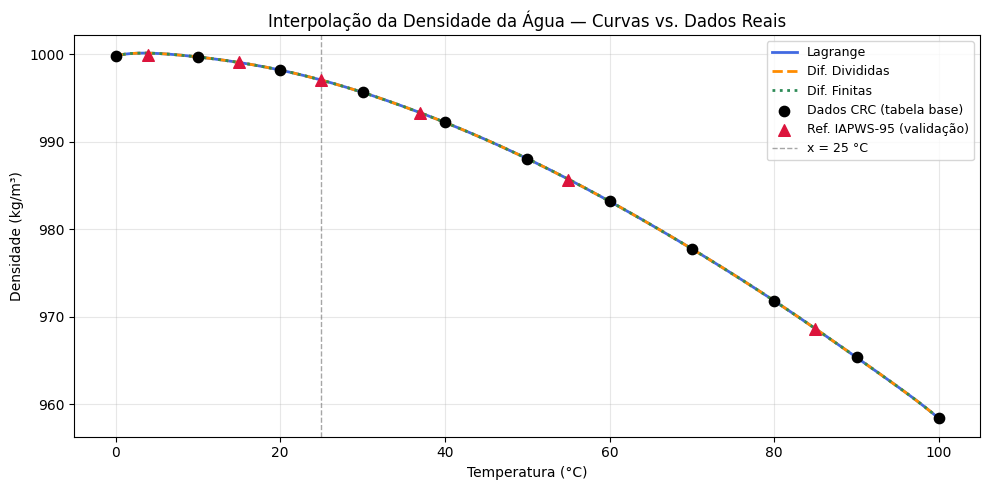

In [ ]:
# ----------------------------------------------------------------------------
# Gráfico 1: Curvas Interpoladas vs. Dados Reais
# ----------------------------------------------------------------------------

x_fino = np.linspace(0, 100, 500)
y_lag_fino = np.array([lagrange(temp, dens, xi) for xi in x_fino])
y_dd_fino  = np.array([avaliar_dd(coefs_dd, temp, xi) for xi in x_fino])
y_df_fino  = np.array([avaliar_df(temp, delta_df, xi) for xi in x_fino])

# Pontos de validação IAPWS-95 para plotar no gráfico
x_val = np.array(list(pontos_val.keys()))
y_val = np.array(list(pontos_val.values()))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_fino, y_lag_fino, label='Lagrange',       color='royalblue',  lw=2)
ax.plot(x_fino, y_dd_fino,  label='Dif. Divididas', color='darkorange', lw=2, ls='--')
ax.plot(x_fino, y_df_fino,  label='Dif. Finitas',   color='seagreen',   lw=2, ls=':')
ax.scatter(temp, dens,  color='black',   zorder=5, s=55, label='Dados CRC (tabela base)')
ax.scatter(x_val, y_val, color='crimson', zorder=6, s=70, marker='^',
           label='Ref. IAPWS-95 (validação)')
ax.axvline(25.0, color='gray', ls='--', lw=1, alpha=0.7, label='x = 25 °C')
ax.set_xlabel('Temperatura (°C)')
ax.set_ylabel('Densidade (kg/m³)')
ax.set_title('Interpolação da Densidade da Água — Curvas vs. Dados Reais')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('grafico1_curvas.png', dpi=150)
plt.show()

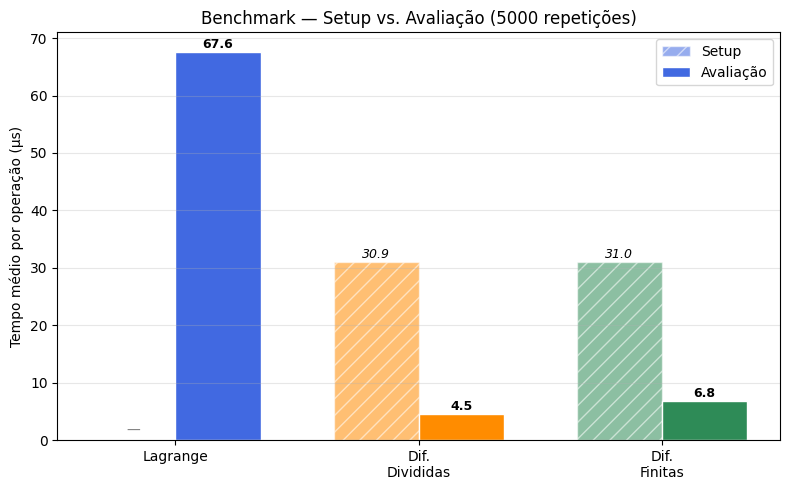

In [ ]:
# ----------------------------------------------------------------------------
# Gráfico 2: Tempo de Setup vs. Avaliação (benchmark justo)
# ----------------------------------------------------------------------------

metodos_plot = ['Lagrange', 'Dif.\nDivididas', 'Dif.\nFinitas']
setups_plot  = [tempo_lag_setup, tempo_dd_setup,  tempo_df_setup]
avals_plot   = [tempo_lag_aval,  tempo_dd_aval,   tempo_df_aval]
cores        = ['royalblue', 'darkorange', 'seagreen']

x_pos = np.arange(len(metodos_plot))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x_pos - width/2, setups_plot, width, label='Setup',    color=cores,
               alpha=0.55, edgecolor='white', hatch='//')
bars2 = ax.bar(x_pos + width/2, avals_plot,  width, label='Avaliação', color=cores,
               edgecolor='white')

for bar, v in zip(bars1, setups_plot):
    if v > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                f'{v:.1f}', ha='center', va='bottom', fontsize=9, style='italic')
    else:
        ax.text(bar.get_x() + bar.get_width()/2, 0.3,
                '—', ha='center', va='bottom', fontsize=10, color='gray')

for bar, v in zip(bars2, avals_plot):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f'{v:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x_pos)
ax.set_xticklabels(metodos_plot)
ax.set_ylabel('Tempo médio por operação (µs)')
ax.set_title(f'Benchmark — Setup vs. Avaliação ({N_REP} repetições)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('grafico2_benchmark.png', dpi=150)
plt.show()

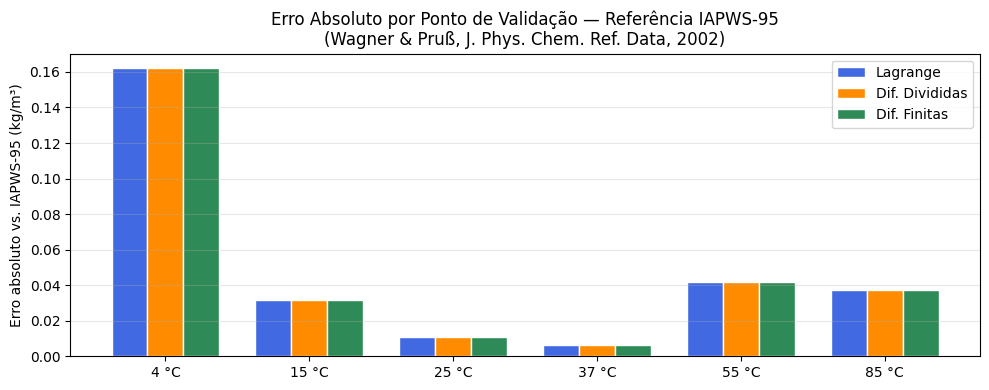

In [ ]:
# ----------------------------------------------------------------------------
# Gráfico 3: Erro por Ponto de Validação (múltiplos pontos)
# ----------------------------------------------------------------------------

x_labels = [f"{x:.0f} °C" for x in pontos_val.keys()]
x_pos2 = np.arange(len(x_labels))
width2 = 0.25

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x_pos2 - width2,   erros_lag, width2, label='Lagrange',       color='royalblue',  edgecolor='white')
ax.bar(x_pos2,             erros_dd,  width2, label='Dif. Divididas', color='darkorange', edgecolor='white')
ax.bar(x_pos2 + width2,   erros_df,  width2, label='Dif. Finitas',   color='seagreen',   edgecolor='white')
ax.set_xticks(x_pos2)
ax.set_xticklabels(x_labels)
ax.set_ylabel('Erro absoluto vs. IAPWS-95 (kg/m³)')
ax.set_title('Erro Absoluto por Ponto de Validação — Referência IAPWS-95\n'
             '(Wagner & Pruß, J. Phys. Chem. Ref. Data, 2002)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('grafico3_erro_multiplos.png', dpi=150)
plt.show()

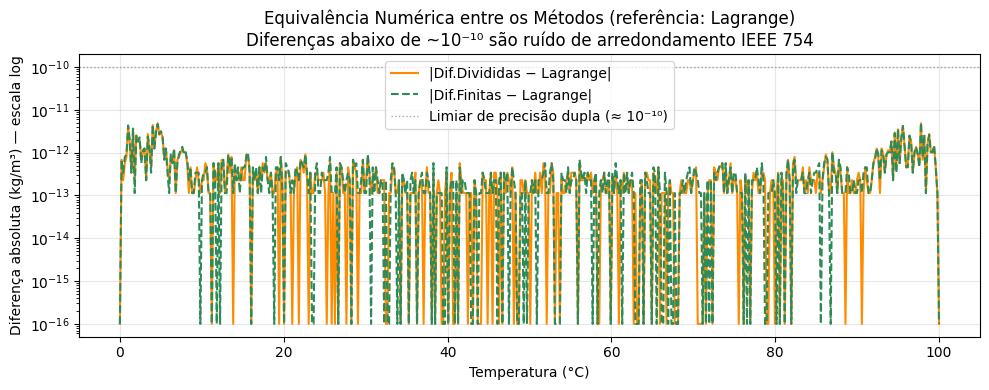

In [ ]:
# ----------------------------------------------------------------------------
# Gráfico 4: Diferença Numérica entre os Métodos (escala log)
# ----------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(x_fino, np.abs(y_dd_fino - y_lag_fino) + 1e-16,
            label='|Dif.Divididas − Lagrange|', color='darkorange', lw=1.5)
ax.semilogy(x_fino, np.abs(y_df_fino - y_lag_fino) + 1e-16,
            label='|Dif.Finitas − Lagrange|',   color='seagreen',   lw=1.5, ls='--')
ax.axhline(1e-10, color='gray', ls=':', lw=1, alpha=0.7,
           label='Limiar de precisão dupla (≈ 10⁻¹⁰)')
ax.set_xlabel('Temperatura (°C)')
ax.set_ylabel('Diferença absoluta (kg/m³) — escala log')
ax.set_title('Equivalência Numérica entre os Métodos (referência: Lagrange)\n'
             'Diferenças abaixo de ~10⁻¹⁰ são ruído de arredondamento IEEE 754')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('grafico4_diferenca.png', dpi=150)
plt.show()